In [1]:
from groq import Groq
import re
import httpx
import os 
from dotenv import load_dotenv, find_dotenv
from openai import OpenAI

_ = load_dotenv(find_dotenv())

In [2]:
client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=os.environ.get("GROQ_API_KEY")
)

In [3]:
chat_completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Hello world"}]
)

In [4]:
chat_completion.choices[0].message.content

'Hello! How can I assist you today?'

In [5]:
class Agent:
    def __init__(self, system=""):
        self.system = system
        self.messages = []
        if self.system:
            self.messages.append({"role": "system", "content": system})

    def __call__(self, messages):
        self.messages.append({"role": "user", "content": messages})
        result = self.execute()
        self.messages.append({"role": "assistant", "content": result})
        return result

    def execute(self):
        completion = client.chat.completions.create(
            model="qwen/qwen3.8-27b",
            temperature=0,
            messages=self.messages
        )
        return completion.choices[0].message.content

In [6]:
prompt = """
You run in a loop of Thought, Action, PAUSE, Observation.
At the end of the loop you output an Answer
Use Thought to describe your thoughts about the question you have been asked.
Use Action to run one of the actions available to you - then return PAUSE.
Observation will be the result of running those actions.

Your available actions are:

calculate:
e.g. calculate: 4 * 7 / 3
Runs a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary

average_dog_weight:
e.g. average_dog_weight: Collie
returns average weight of a dog when given the breed

Example session:

Question: How much does a Bulldog weigh?
Thought: I should look the dogs weight using average_dog_weight
Action: average_dog_weight: Bulldog
PAUSE

You will be called again with this:

Observation: A Bulldog weights 51 lbs

You then output:

Answer: A bulldog weights 51 lbs
""".strip()

In [7]:
def calculate(what):
    return eval(what)

def average_dog_weight(name):
    if name in "Scottish Terrier":
        return("Scottish Terriers average 20 lbs")
    elif name in "Border Collie":
        return("a Border Collie average weight is 37 lbs")
    elif name in "Toy Poodle":
        return("a toy poodles average weight is 7 lbs")
    else:
        return("An average dog weights 50 lbs")

known_actions = {
    "calculate": calculate,
    "average_dog_weight": average_dog_weight
}

In [8]:
abot = Agent(prompt)

In [9]:
result = abot("How much does a toy poodle weight?")
print(result)

Thought: I need to find the average weight of a Toy Poodle. I can use the average_dog_weight tool with the breed "Toy Poodle".
Action: average_dog_weight: Toy Poodle
PAUSE


In [10]:
result = average_dog_weight("Toy Poodle")
result

'a toy poodles average weight is 7 lbs'

In [11]:
next_prompt = "Observation: {}".format(result)
abot(next_prompt)

'Answer: A Toy Poodle weighs an average of 7 lbs.'

In [12]:
abot.messages

[{'role': 'system',
  'content': 'You run in a loop of Thought, Action, PAUSE, Observation.\nAt the end of the loop you output an Answer\nUse Thought to describe your thoughts about the question you have been asked.\nUse Action to run one of the actions available to you - then return PAUSE.\nObservation will be the result of running those actions.\n\nYour available actions are:\n\ncalculate:\ne.g. calculate: 4 * 7 / 3\nRuns a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary\n\naverage_dog_weight:\ne.g. average_dog_weight: Collie\nreturns average weight of a dog when given the breed\n\nExample session:\n\nQuestion: How much does a Bulldog weigh?\nThought: I should look the dogs weight using average_dog_weight\nAction: average_dog_weight: Bulldog\nPAUSE\n\nYou will be called again with this:\n\nObservation: A Bulldog weights 51 lbs\n\nYou then output:\n\nAnswer: A bulldog weights 51 lbs'},
 {'role': 'user', 'content': 'How much does a 

In [13]:
abot = Agent(prompt)

In [14]:
question = """I have 2 dogs, a border collie and a scottish terrie. \
What is there combined weight"""
abot(question)

'Thought: I need to find the average weight of a Border Collie and a Scottish Terrier, then add them together. I will start by finding the average weight of a Border Collie.\nAction: average_dog_weight: Border Collie\nPAUSE'

In [15]:
next_prompt = "Observation: {}".format(average_dog_weight("Border Collie"))
print(next_prompt)

Observation: a Border Collie average weight is 37 lbs


In [16]:
abot(next_prompt)

'Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of a Scottish Terrier.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [17]:
next_prompt = "Observation: {}".format(average_dog_weight("scottish Terrier"))
print(next_prompt)

Observation: An average dog weights 50 lbs


In [18]:
abot(next_prompt)

'Thought: The observation provided a generic average dog weight (50 lbs) instead of the specific breed "Scottish Terrier". I should try the action again with the specific breed name to see if I can get a more accurate result. If not, I might have to use the generic average or look for another way. Let\'s try "Scottish Terrier" again.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [19]:
next_prompt = "Observation: {}".format(eval("37 + 20"))
print(next_prompt)

Observation: 57


In [20]:
abot(next_prompt)

'Thought: The second attempt returned "57", which is likely the average weight in lbs for a Scottish Terrier. Now I have the weights for both dogs:\n- Border Collie: 37 lbs\n- Scottish Terrier: 57 lbs\n\nI need to calculate their combined weight.\nAction: calculate: 37 + 57\nPAUSE'

In [21]:
action_re = re.compile('^Action: (\w+): (.*)$')

In [22]:
def query(question, max_turns=5):
    i = 0
    bot = Agent(prompt)
    next_prompt = question
    while i < max_turns:
        i += 1
        result = bot(next_prompt)
        print(result)
        actions = [
            action_re.match(a) 
            for a in result.split('\n') 
            if action_re.match(a)
        ]
        if actions:
            action, action_input = actions[0].groups()
            if action not in known_actions:
                raise Exception("Unknown action: {}: {}".format(action, action_input))
            print(" -- running {} {}".format(action, action_input))
            observation = known_actions[action](action_input)
            print("Observation:", observation)
            next_prompt = "Observation: {}".format(observation)
        else:
            return

In [23]:
question = """I have 2 dogs, a border collie and a scottish terrier. \
What is their combined weight"""
query(question)

Thought: I need to find the average weight of a Border Collie and the average weight of a Scottish Terrier. Then I will sum these two weights to find the combined weight. I will start by finding the weight of the Border Collie.
Action: average_dog_weight: Border Collie
PAUSE
 -- running average_dog_weight Border Collie
Observation: a Border Collie average weight is 37 lbs
Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of the Scottish Terrier.
Action: average_dog_weight: Scottish Terrier
PAUSE
 -- running average_dog_weight Scottish Terrier
Observation: Scottish Terriers average 20 lbs
Thought: I have the average weight for both dogs. The Border Collie is 37 lbs and the Scottish Terrier is 20 lbs. I need to add these two numbers together to get the combined weight.
Action: calculate: 37 + 20
PAUSE
 -- running calculate 37 + 20
Observation: 57
Answer: The combined weight of your Border Collie and Scottish Terrier is 57 lbs.


# LangGraph

In [24]:
from dotenv import load_dotenv
_ = load_dotenv()

In [ ]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_openai import ChatOpenAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_groq import ChatGroq
#from langchain_google_genai import ChatGoogleGenerativeAI

/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/googl

In [ ]:
tool = TavilySearchResults(max_results=1) #increased number of results
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/var/folders/lp/z2zxddwj6vn0tff42w5ph1_00000gn/T/ipykernel_51930/144666821.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=4) #increased number of results


In [27]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [28]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:      # check for bad tool name from LLM
                print("\n ....bad tool name....")
                result = "bad tool name, retry"  # instruct LLM to retry if bad
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

In [32]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

#model = ChatGroq(model="qwen/qwen3.8-27b")  #reduce inference cost
model = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    google_api_key=os.environ.get("GEMINI_API_KEY")
)
abot = Agent(model, [tool], system=prompt)

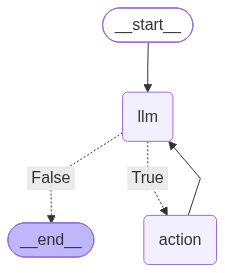

In [33]:
from IPython.display import Image, display

display(Image(abot.graph.get_graph().draw_mermaid_png()))

In [34]:
messages = [HumanMessage(content="What is the weather in sf?")]
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather San Francisco'}, 'id': 'b29e2b10-0c42-42c8-992b-934aa0c31601', 'type': 'tool_call'}
Back to the model!


ChatGoogleGenerativeAIError: Invalid argument provided to Gemini: 400 Function call is missing a thought_signature in functionCall parts. This is required for tools to work correctly, and missing thought_signature may lead to degraded model performance. Additional data, function call `default_api:tavily_search_results_json` , position 2. Please refer to https://ai.google.dev/gemini-api/docs/thought-signatures for more details.

In [ ]:
result

{'messages': [HumanMessage(content='What is the weather in sf?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'z1ppspbvq', 'function': {'arguments': '{"query":"current weather in San Francisco"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 381, 'total_tokens': 414, 'completion_time': 0.09816469, 'completion_tokens_details': None, 'prompt_time': 0.025973831, 'prompt_tokens_details': None, 'queue_time': 0.058166938, 'total_time': 0.124138521}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--01a11050-5d83-7ce0-934a-913d8b0828a5-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'z1ppspbvq', 'type': 'tool_call'}], usage_metadata={'input_tokens': 381, 'outpu

In [ ]:
result['messages'][-1].content

"Here's the current weather in San Francisco:\n\n**Today:**\n- **Temperature:** In the 70s °F (a ~10° increase from yesterday)\n- **Conditions:** Crystal clear skies, sunny, and dry — a gorgeous day\n- **Coastline:** In the 60s °F\n- **Humidity:** Very low (dropping below 10% in some areas — bone dry)\n\n**Outlook:**\n- A high pressure ridge is building in, bringing northerly/northeasterly winds that push dry interior air out to the Bay\n- **Tomorrow and into the weekend:** Scorching hot conditions expected\n- **Interior Bay Area:** San Jose/Santa Clara ~89°F, Livermore ~96°F, Oakland/Berkeley low 80s, Vacaville hitting 100°F\n- **Fire risk:** Peak/very high fire danger in the East Bay and North Bay hills (Diablo Range, Mt. Hamilton, Solano/Napa/Lake County elevations)\n\nSo it's a beautiful but very dry, warm day in SF — great for getting out, but with elevated fire risk in the surrounding hills. Want me to dig up anything more specific, like the hourly forecast or fog predictions?"

In [ ]:
messages = [HumanMessage(content="What is the weather in SF and LA?")]
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco today'}, 'id': 'f4e0a86d9', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in Los Angeles today'}, 'id': 'c8q9xnazj', 'type': 'tool_call'}
Back to the model!


APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `qwen/qwen3.8-27b` in organization `org_01kjfpdavze77twghmm4dthk7z` service tier `on_demand` on input tokens per minute (ITPM): Limit 7000, Requested 7665, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

In [ ]:
result['messages'][-1].content

"Here's the current weather in San Francisco:\n\n**Today:**\n- **Temperature:** In the 70s °F (a ~10° increase from yesterday)\n- **Conditions:** Crystal clear skies, sunny, and dry — a gorgeous day\n- **Coastline:** In the 60s °F\n- **Humidity:** Very low (dropping below 10% in some areas — bone dry)\n\n**Outlook:**\n- A high pressure ridge is building in, bringing northerly/northeasterly winds that push dry interior air out to the Bay\n- **Tomorrow and into the weekend:** Scorching hot conditions expected\n- **Interior Bay Area:** San Jose/Santa Clara ~89°F, Livermore ~96°F, Oakland/Berkeley low 80s, Vacaville hitting 100°F\n- **Fire risk:** Peak/very high fire danger in the East Bay and North Bay hills (Diablo Range, Mt. Hamilton, Solano/Napa/Lake County elevations)\n\nSo it's a beautiful but very dry, warm day in SF — great for getting out, but with elevated fire risk in the surrounding hills. Want me to dig up anything more specific, like the hourly forecast or fog predictions?"

In [ ]:
# Note, the query was modified to produce more consistent results. 
# Results may vary per run and over time as search information and models change.

query = "Who won the super bowl in 2024? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question." 
messages = [HumanMessage(content=query)]

model = ChatOpenAI(model="gpt-4o")  # requires more advanced model
abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})

OpenAIError: The api_key client option must be set either by passing api_key to the client or by setting the OPENAI_API_KEY environment variable

In [ ]:
print(result['messages'][-1].content)